<p style="width: 525px; height: 200px;">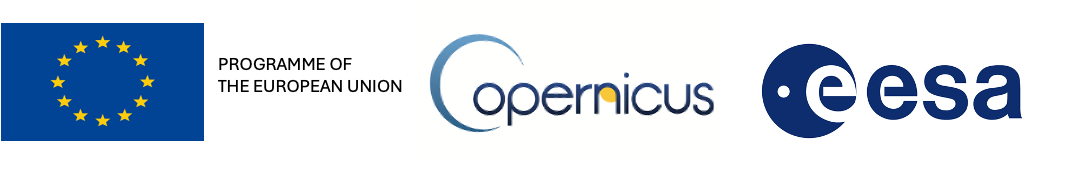</p>

# Run SENTINEL-1 ARD processor

In [ ]:
"""
File Name: wf_sentinel_1.ipynb

Author:
    Alessio Morea
    B-Open Solutions srl

Date: August 2025

Description:
------------
This notebook processes Sentinel-1 data to generate Analysis-Ready Data (ARD) products, specifically CSLC, NRB and GSLC.
Options and configuration parameters about some processing steps can be set
by the user.

Usage:
------
To use this script, define the following parameters:

    - dem_path:  Path to the input Digital Elevation Model (DEM) file.
    - slcs_path: Path to the directory containing the SLCs
    - wdir_path_static: Directory to save static data
    - wdir_path_tmp: Directory to save dynamic data
    - reference_date:  The acquisition date of the reference image
    - spacing: The output pixel spacing for the resampled DEM.

Optionally, set the processing parameters:
    - etad_path:  Path to the folder containing ETAD correction files.
    - orbit_path: Path to the folder containing precise orbit files 
    - chunks: The chunk size to use for parallel computations
    - crs: The target CRS for DEM reprojection 
    - recompute: Set to True to force recomputation of files in the static directory. Defaults to False.
    - apply_flattening:  Set to False to disable flattening. Defaults to True. Changing this option does not require recomputing data in the static directory.
    - n_jobs:  The number of parallel workers to use.
    - job_memory: The memory allocated to each worker
"""

In [ ]:
%load_ext autoreload
%autoreload 2
import warnings

import os
import time
import pyproj
import numpy as np
import xarray as xr
import s1_ard_core.computing.io
import s1_ard_core.computing.dem
import s1_ard_core.computing.simul
import s1_ard_core.computing.shiroma

import s1_ard_core.computing.slc
import s1_ard_core.computing.orbit
import s1_ard_core.computing.etad
import s1_ard_core.computing.gslc
import s1_ard_core.computing.coreg
from s1_ard_core.computing.logger import logger
from pyproj.transformer import TransformerGroup
warnings.filterwarnings("ignore")

### Processor configuration

Define paths and variables

In [2]:
prefix_path = "/home/morea/SENTINEL1/SALZBURG/44"
dem_path = f"{prefix_path}/INPUT_DATA/dem"
slcs_path = f"{prefix_path}/INPUT_DATA/slcs"
wdir_path_static = f"{prefix_path}/ESA/WDIR_STATIC"
wdir_path_tmp = f"{prefix_path}/ESA/WDIR_DYNAMIC"
etad_path = f"{prefix_path}/SAFE"
orbit_path = None
reference_date = "2024-10-15"
chunks = {"x": 1024, "y": 1024}
spacing = {"x": 0.3 / 3600, "y": 0.3 / 3600}
apply_flattening = True
crs = 4326
recompute = False
n_jobs = 16
job_memory = "16GB"

### Create Dask Client

In [ ]:
os.environ["PROJ_DATA"] = pyproj.datadir.get_data_dir()
client = s1_ard_core.computing.computation.create_client("LOCAL", n_jobs, job_memory)
client

### Read L1 Data

In [ ]:
slcs = s1_ard_core.computing.io.read(slcs_path, consolidate_metadata=True)
bbox = s1_ard_core.computing.slc.get_bbox(slcs)
multiburst = True if "bursts" in slcs else False
acquisition_dates = s1_ard_core.computing.slc.extract_acquisition_dates(slcs, multiburst=multiburst)
if orbit_path is not None:
    slcs = s1_ard_core.computing.orbit.import_ORBIT(slcs, acquisition_dates, orbit_path, multiburst=multiburst)
if etad_path is not None:
    slcs = s1_ard_core.computing.etad.import_ETAD(
        slcs, acquisition_dates, etad_path, multiburst=multiburst, wdir_path=wdir_path_tmp
    )

### Import DEM and Resampling

In [ ]:
dem = s1_ard_core.computing.dem.import_dem(
    bbox=bbox,
    dem_type=dem_path,
    working_dir=wdir_path_tmp,
    chunks=chunks,
)
if crs is None:
    crs = s1_ard_core.computing.dem.get_default_epsg(dem)
dem_resampled = s1_ard_core.computing.dem.dem_reproject(
    dem, spacing, crs, chunks=chunks, data_path=wdir_path_tmp, enable_dask=True
)

### Reference Geometry

In [ ]:
dem_resampled = s1_ard_core.computing.io.read(f"{wdir_path_tmp}/dem_resampled", consolidate_metadata=False)

In [ ]:
orbits = s1_ard_core.computing.slc.extract_orbits(
    slcs,
    multiburst=multiburst,
    acquisition_date=[reference_date],
)
orbits = orbits.sel(acquisition_date=[reference_date])
chunks = {k: v[0] for k, v in dem_resampled.chunksizes.items() if k in ["x", "y"]}
chunks["acquisition_date"] = 1
simulation = s1_ard_core.computing.simul.dem_to_radar(
    dem_resampled.z,
    orbits,
    working_dir=wdir_path_static,
    chunks=chunks,
    read=True,
    master_image=True,
    recompute=recompute,
)
simulation_ml = s1_ard_core.computing.simul.extract_simulation_ml(
    simulation, reference_date, wdir_path_static, recompute=recompute
)

### Rasterization and RTC (Area Based)

In [ ]:
t0 = time.time()
s1_ard_core.computing.shiroma.stack_geometry(
    slcs,
    simulation,
    simulation_ml,
    working_directory_static=wdir_path_static,
    working_directory_tmp=wdir_path_tmp,
    reference_date=reference_date,
    chunk_length=max([i for i in chunks.values()]),
    recompute=recompute,
    multiburst=multiburst,
)
t1 = time.time() - t0
print(f"TIME RASTERIZATION + RTC_AP: {t1:.8f} s")

### Compute Radar Shadow Mask

In [ ]:
t0 = time.time()
s1_ard_core.computing.shiroma.stack_mask(
    slcs,
    simulation,
    simulation_ml,
    working_directory_static=wdir_path_static,
    reference_date=reference_date,
    recompute=recompute,
    multiburst=multiburst,
)
t1 = time.time() - t0
print(f"TIME MASK SHADOW: {t1:.4f} s")

## CSLC product generation 

In [ ]:
orbits = s1_ard_core.computing.slc.extract_orbits(slcs, multiburst=multiburst)
orbits = orbits.where(orbits.acquisition_date != reference_date, drop=True)
chunks = {k: v[0] for k, v in dem_resampled.chunksizes.items() if k in ["x", "y"]}
chunks["acquisition_date"] = 1
if orbits.acquisition_date.size != 0:
    simulation_coreg = s1_ard_core.computing.simul.dem_to_radar(
        dem_resampled.z,
        orbits,
        working_dir=wdir_path_tmp,
        chunks=chunks,
        client_options={"type": "LOCAL"},
        read=True,
        master_image=False,
    )
    simulation_combined = xr.concat([simulation, simulation_coreg], dim="acquisition_date").chunk(
        {k: v[0] for k, v in simulation.chunksizes.items()}
    )

    simulation_combined = s1_ard_core.computing.io.write(
        simulation_combined,
        f"{wdir_path_tmp}/simulation.combined",
        mode="w",
        consolidated=False,
    )
else:
    simulation_combined = simulation

In [ ]:
orbits = s1_ard_core.computing.slc.extract_orbits(slcs, multiburst=multiburst)
orbits = orbits.where(orbits.acquisition_date != reference_date, drop=True)
if orbits.acquisition_date.size != 0:
    simulation_combined = s1_ard_core.computing.io.read(
        f"{wdir_path_tmp}/simulation.combined", consolidate_metadata=False
    )
else:
    simulation_combined = simulation

In [ ]:
t0 = time.time()
slcs = s1_ard_core.computing.coreg.stack_coregistration(
    slcs,
    simulation_combined,
    simulation_ml,
    reference_date,
    multiburst=multiburst,
    working_directory=wdir_path_tmp,
)
t1 = time.time() - t0
print(f"TIME COREG: {t1:.8f} s")

## NRB product generation - Area based projection

In [ ]:
files = s1_ard_core.computing.io.glob(f"{wdir_path_tmp}/bursts/iw*")
for f in files:
    k = f.split("/")[-1]
    slcs[f"bursts/{k}/coreg"] = s1_ard_core.computing.io.read(f, consolidate_metadata=True)["coreg"]

In [ ]:
t0 = time.time()
gslcs = s1_ard_core.computing.gslc.stack_shiroma(
    slcs=slcs,
    reference_date=reference_date,
    multiburst=multiburst,
    coreg=True,
    working_directory_static=wdir_path_static,
    working_directory_tmp=wdir_path_tmp,
    recompute=recompute,
    apply_flattening=apply_flattening,
)
t1 = time.time() - t0
print(f"TIME FLATTENING + PROJECTION: {t1:.4f} s")

In [ ]:
t0 = time.time()
nrb = s1_ard_core.computing.gslc.mosaic(gslcs, wdir_path_tmp)
t1 = time.time() - t0
print(f"TIME MOSAIC: {t1:.4f} s")

In [4]:
nrb

<xarray.Dataset> Size: 29GB
Dimensions:           (y: 22306, x: 45848, polarization: 2, acquisition_date: 1)
Coordinates:
  * acquisition_date  (acquisition_date) <U10 40B '2024-10-15'
  * polarization      (polarization) <U3 24B 'V:H' 'V:V'
    spatial_ref       int64 8B ...
  * x                 (x) float64 367kB 11.15 11.15 11.15 ... 14.97 14.97 14.97
  * y                 (y) float64 178kB 46.7 46.7 46.7 ... 48.55 48.55 48.55
Data variables:
    anf               (y, x) float32 4GB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
    burst_id          (y, x) int32 4GB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
    gamma0            (polarization, acquisition_date, y, x) float32 8GB dask.array<chunksize=(1, 1, 1024, 1024), meta=np.ndarray>
    lia               (y, x) float32 4GB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
    mask              (y, x) int32 4GB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
    nlooks            (y, x) float32 4GB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
Attributes:
    CRS_EPSG:    4326
    CRS_WKT:     GEOGCRS["WGS 84",ENSEMBLE["World Geodetic System 1984 ensemb...
    legend:      {'0': 'iw1_92638', '1': 'iw1_92639', '10': 'iw2_92639', '11'...
    obj_type:    xr.Dataset
    store_path:  /home/morea/SENTINEL1/SALZBURG/44/ESA/WDIR_DYNAMIC/nrb

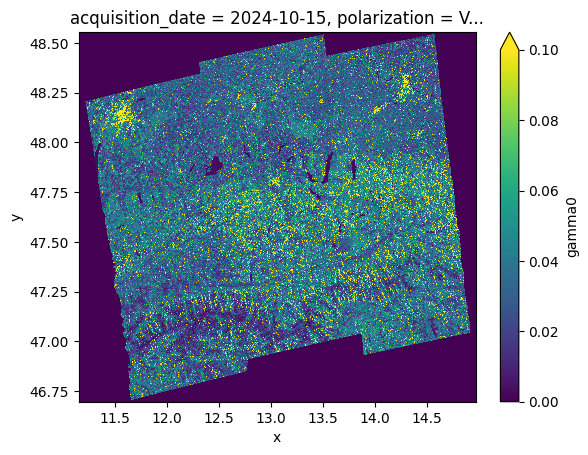

In [6]:
nrb.gamma0[0, 0].coarsen(x=10, y=10, boundary="trim").mean().plot.imshow(vmin=0, vmax=0.1)

## GSLC product generation - Point based projection

In [ ]:
gslcs = s1_ard_core.computing.gslc.stack_geocoding(
    slcs, simulation, simulation_ml, wdir_path_static, wdir_path_tmp, multiburst=multiburst, gamma_flattening=apply_flattening
)